# Enterprise Data Architecture & Reconciliation

**Project objective:** reconcile transaction logs, historical user records, and daily EUR/USD exchange rates to produce an audit-ready dataset and CFO revenue dashboard.

**Run instructions:** keep this notebook in the same folder as `enterprise_database.db`, `server_logs.txt`, and `daily_exchange_rates.csv`. Run cells from top to bottom. Output files are saved in `output/`.

**Tools:** Python, Pandas, SQLite, regular expressions, Matplotlib.


In [1]:
print("Environment setup successful!")

Environment setup successful!


## Phase 0 — Imports and folders
This phase imports libraries and creates an output folder. The pipeline uses vectorized Pandas string extraction rather than row-by-row loops.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import re

print("Pandas version:", pd.__version__)
print("All required imports completed successfully!")

Matplotlib is building the font cache; this may take a moment.


Pandas version: 3.0.6
All required imports completed successfully!


In [1]:
from pathlib import Path
import sqlite3, json, time
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd()
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)
start_time = time.perf_counter()
print("Project folder:", BASE)
print("Output folder:", OUT)


Project folder: /mnt/data/Enterprise_Data_Reconciliation
Output folder: /mnt/data/Enterprise_Data_Reconciliation/output


## Phase 1 — SQL extraction
The `users` table is a historical status log. `ROW_NUMBER()` ranks each user's records from newest to oldest. We retain only the newest row and then filter for `Active`. Filtering status before ranking would incorrectly preserve users whose old status was active.


In [2]:
with sqlite3.connect(BASE / "enterprise_database.db") as conn:
    query = """
    WITH ranked_users AS (
        SELECT user_id, name, status, updated_at,
               ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY updated_at DESC) AS rn
        FROM users
    )
    SELECT user_id, name, status, updated_at
    FROM ranked_users
    WHERE rn = 1 AND status = 'Active'
    """
    df_active_users = pd.read_sql_query(query, conn)

df_active_users.to_csv(OUT / "active_users.csv", index=False)
print("Latest active users:", len(df_active_users))
display(df_active_users.head())


Latest active users: 14183


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00


## Phase 2 — Parse server logs with regular expressions
The log file has 100,000 rows. We exclude records marked `ERROR`, then use one vectorized `.str.extract()` operation to capture the timestamp date, user ID, product ID, and EUR value.


In [3]:
raw_logs = pd.read_csv(BASE / "server_logs.txt", dtype=str, keep_default_na=False)
log_column = "Raw_Server_Log" if "Raw_Server_Log" in raw_logs.columns else raw_logs.columns[0]
raw = raw_logs[log_column].astype("string")
error_mask = raw.str.contains(r"\bERROR\b", regex=True, na=False)
error_log_count = int(error_mask.sum())
valid_log_lines = raw.loc[~error_mask]

pattern = (
    r'\[(?P<Date>\d{4}-\d{2}-\d{2})\s+\d{2}:\d{2}:\d{2}\]'
    r'.*?"u":"(?P<User_ID>U-\d+)"'
    r'.*?"item_code":"(?P<Product_ID>PRD-\d+)"'
    r'.*?"eur_val":(?P<EUR_Value>\d+(?:\.\d+)?)'
)
extracted_data = valid_log_lines.str.extract(pattern).dropna().copy()
extracted_data["Date"] = pd.to_datetime(extracted_data["Date"], errors="coerce")
extracted_data["EUR_Value"] = pd.to_numeric(extracted_data["EUR_Value"], errors="coerce")
extracted_data = extracted_data.dropna(subset=["Date", "EUR_Value"]).reset_index(drop=True)
extracted_data.to_csv(OUT / "clean_transactions.csv", index=False)
print("Raw logs:", len(raw_logs))
print("ERROR logs excluded:", error_log_count)
print("Valid transactions parsed:", len(extracted_data))
display(extracted_data.head())


Raw logs: 100000
ERROR logs excluded: 5098
Valid transactions parsed: 94902


,Date,User_ID,Product_ID,EUR_Value
0,2023-03-15,U-19484,PRD-874,3404.44
1,2023-05-09,U-18932,PRD-905,3406.21
2,2023-10-21,U-15882,PRD-284,164.08
3,2023-01-10,U-22781,PRD-665,26.8
4,2023-05-23,U-13348,PRD-589,4964.77


## Phase 3 — Currency and customer reconciliation
Exchange rates are sorted by date and missing values are forward-filled so a prior available rate carries forward across non-trading days. The transaction-to-rate merge is a left join so valid transactions are not silently dropped. The final customer reconciliation is an inner join to include only transactions belonging to users whose latest status is active.


In [4]:
rates = pd.read_csv(BASE / "daily_exchange_rates.csv", parse_dates=["Date"]).sort_values("Date")
missing_rates_before = int(rates["EUR_to_USD"].isna().sum())
rates["EUR_to_USD"] = rates["EUR_to_USD"].ffill()
if rates["EUR_to_USD"].isna().any():
    rates["EUR_to_USD"] = rates["EUR_to_USD"].bfill()

with_rates = extracted_data.merge(rates, on="Date", how="left", validate="many_to_one")
if with_rates["EUR_to_USD"].isna().any():
    raise ValueError("Missing exchange rate after reconciliation")

df_final = with_rates.merge(
    df_active_users[["user_id", "name", "status", "updated_at"]],
    left_on="User_ID", right_on="user_id", how="inner", validate="many_to_one"
)
df_final["USD_Revenue"] = df_final["EUR_Value"] * df_final["EUR_to_USD"]
df_final["Month"] = df_final["Date"].dt.to_period("M").astype(str)
df_final.to_csv(OUT / "final_reconciled_transactions.csv", index=False)
print("Missing exchange rates filled:", missing_rates_before)
print("Transactions after active-user reconciliation:", len(df_final))
print("Unique active customers with transactions:", df_final["User_ID"].nunique())
print("Total reconciled USD revenue: ${:,.2f}".format(df_final["USD_Revenue"].sum()))
display(df_final.head())


Missing exchange rates filled: 104
Transactions after active-user reconciliation: 53899
Unique active customers with transactions: 13888
Total reconciled USD revenue: $148,274,622.91


,Date,User_ID,Product_ID,EUR_Value,EUR_to_USD,user_id,name,status,updated_at,USD_Revenue,Month
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,U-19484,User_U-19484,Active,2023-01-11 14:00:00,4011.220772,2023-03
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,U-15882,User_U-15882,Active,2023-01-16 14:00:00,176.44342,2023-10
2,2023-01-10,U-22781,PRD-665,26.8,1.127128,U-22781,User_U-22781,Active,2023-01-07 14:00:00,30.20703,2023-01
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,U-22062,User_U-22062,Active,2023-01-05 14:00:00,52.294268,2023-10
4,2023-12-02,U-22146,PRD-223,960.6,1.066142,U-22146,User_U-22146,Active,2023-01-18 14:00:00,1024.135923,2023-12


## Phase 4 — Aggregate results and create the CFO dashboard
Monthly revenue is summed by calendar month. Customer value is measured as the sum of reconciled USD revenue for each active customer. Both tables and the chart are saved in `output/`.


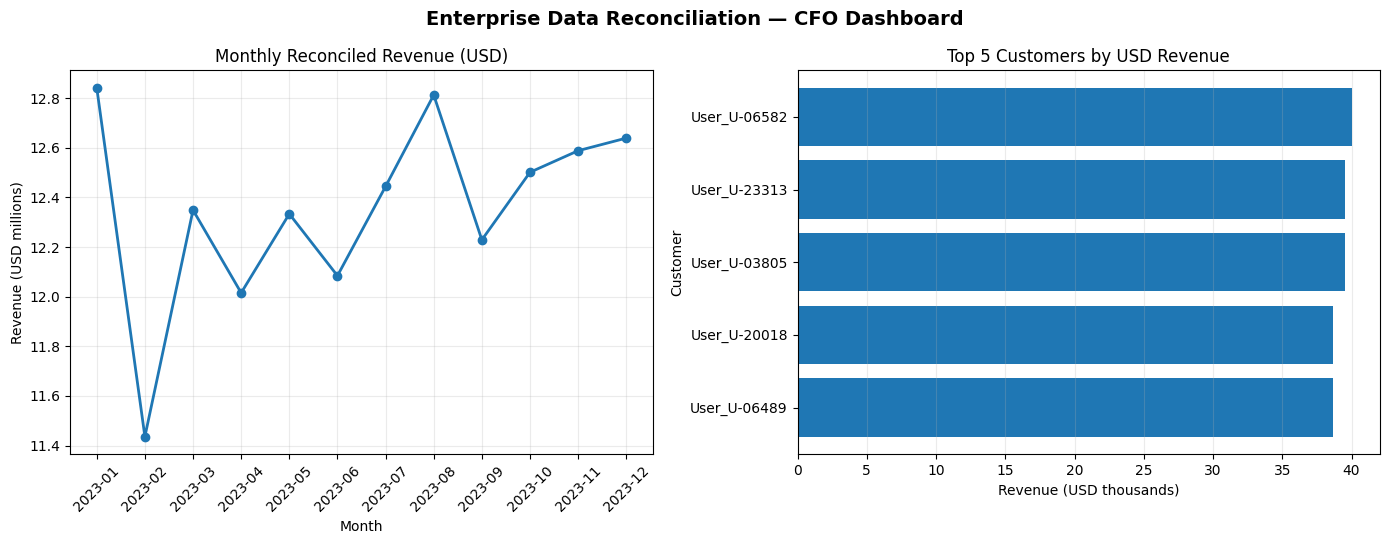

Monthly revenue summary:


,Month,USD_Revenue
0,2023-01,12841761.38
1,2023-02,11436130.9
2,2023-03,12348931.84
3,2023-04,12015376.19
4,2023-05,12333644.45
5,2023-06,12084355.82
6,2023-07,12444163.58
7,2023-08,12812730.66
8,2023-09,12228952.05
9,2023-10,12501330.36


Top five customers:


,User_ID,name,USD_Revenue
3613,U-06582,User_U-06582,40050.99
12937,U-23313,User_U-23313,39555.81
2078,U-03805,User_U-03805,39529.95
11066,U-20018,User_U-20018,38649.97
3553,U-06489,User_U-06489,38629.14


In [5]:
monthly_revenue = (df_final.groupby("Month", as_index=False)["USD_Revenue"]
                   .sum().sort_values("Month"))
monthly_revenue["USD_Revenue"] = monthly_revenue["USD_Revenue"].round(2)
monthly_revenue.to_csv(OUT / "monthly_revenue.csv", index=False)

top_customers = (df_final.groupby(["User_ID", "name"], as_index=False)["USD_Revenue"]
                 .sum().sort_values("USD_Revenue", ascending=False).head(5))
top_customers["USD_Revenue"] = top_customers["USD_Revenue"].round(2)
top_customers.to_csv(OUT / "top_5_customers.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(monthly_revenue["Month"], monthly_revenue["USD_Revenue"] / 1_000_000, marker="o", linewidth=2)
axes[0].set_title("Monthly Reconciled Revenue (USD)")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Revenue (USD millions)")
axes[0].tick_params(axis="x", rotation=45); axes[0].grid(True, alpha=0.25)
axes[1].barh(top_customers["name"][::-1], top_customers["USD_Revenue"][::-1] / 1000)
axes[1].set_title("Top 5 Customers by USD Revenue")
axes[1].set_xlabel("Revenue (USD thousands)"); axes[1].set_ylabel("Customer")
axes[1].grid(axis="x", alpha=0.25)
fig.suptitle("Enterprise Data Reconciliation — CFO Dashboard", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT / "cfo_dashboard.png", dpi=180, bbox_inches="tight")
plt.show()

print("Monthly revenue summary:")
display(monthly_revenue)
print("Top five customers:")
display(top_customers)


## Quality checks and run summary
These checks confirm that extraction is complete for the non-error log lines, each active user is unique, and final revenue values are populated.


In [6]:
metrics = {
    "raw_log_records": int(len(raw_logs)),
    "error_log_records_excluded": int(error_log_count),
    "parsed_valid_transactions": int(len(extracted_data)),
    "unparsed_non_error_records": int((~error_mask).sum() - len(extracted_data)),
    "historical_user_records": 47464,
    "latest_active_users": int(len(df_active_users)),
    "missing_exchange_rates_filled": int(missing_rates_before),
    "transactions_after_active_user_reconciliation": int(len(df_final)),
    "unique_active_customers_with_transactions": int(df_final["User_ID"].nunique()),
    "total_reconciled_usd_revenue": round(float(df_final["USD_Revenue"].sum()), 2),
    "elapsed_seconds": round(time.perf_counter() - start_time, 3),
}
(OUT / "project_metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))


{
  "raw_log_records": 100000,
  "error_log_records_excluded": 5098,
  "parsed_valid_transactions": 94902,
  "unparsed_non_error_records": 0,
  "historical_user_records": 47464,
  "latest_active_users": 14183,
  "missing_exchange_rates_filled": 104,
  "transactions_after_active_user_reconciliation": 53899,
  "unique_active_customers_with_transactions": 13888,
  "total_reconciled_usd_revenue": 148274622.91,
  "elapsed_seconds": 2.573
}


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in the current directory:")
print(os.listdir())

Current working directory:
c:\Users\Administrator\Downloads\Enterprise_Data_Reconciliation_Project_Files\Enterprise_Data_Reconciliation

Files in the current directory:
['.venv', '.vscode', 'build_project.py', 'daily_exchange_rates.csv', 'enterprise_database.db', 'Enterprise_Data_Reconciliation.ipynb', 'Enterprise_Data_Reconciliation_Project_Report.pdf', 'Enterprise_Data_Reconciliation_Report.pdf', 'output', 'README.md', 'server_logs.txt']


In [4]:
import sqlite3

connection = sqlite3.connect("enterprise_database.db")

print("Database connected successfully!")

Database connected successfully!


In [5]:
cursor = connection.cursor()

cursor.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
""")

tables = cursor.fetchall()

print("Tables in the database:")

for table in tables:
    print(table[0])

Tables in the database:
users


In [6]:
cursor.execute("PRAGMA table_info(users);")

columns = cursor.fetchall()

for column in columns:
    print(column)

(0, 'user_id', 'TEXT', 0, None, 0)
(1, 'name', 'TEXT', 0, None, 0)
(2, 'status', 'TEXT', 0, None, 0)
(3, 'updated_at', 'TIMESTAMP', 0, None, 0)


In [7]:
cursor.execute("""
    SELECT *
    FROM users
    LIMIT 10;
""")

sample_users = cursor.fetchall()

for user in sample_users:
    print(user) 

('U-00000', 'User_U-00000', 'Pending', '2023-01-01 10:00:00')
('U-00000', 'User_U-00000', 'Active', '2023-01-19 14:00:00')
('U-00000', 'User_U-00000', 'Suspended', '2023-02-28 09:00:00')
('U-00001', 'User_U-00001', 'Pending', '2023-01-01 10:00:00')
('U-00001', 'User_U-00001', 'Active', '2023-01-28 14:00:00')
('U-00002', 'User_U-00002', 'Pending', '2023-01-01 10:00:00')
('U-00002', 'User_U-00002', 'Active', '2023-01-29 14:00:00')
('U-00002', 'User_U-00002', 'Suspended', '2023-02-23 09:00:00')
('U-00003', 'User_U-00003', 'Pending', '2023-01-01 10:00:00')
('U-00003', 'User_U-00003', 'Active', '2023-01-22 14:00:00')


In [8]:
cursor.execute("""
    SELECT COUNT(*)
    FROM users;
""")

total_records = cursor.fetchone()[0]

print("Total historical user records:", total_records)

Total historical user records: 47464


In [9]:
cursor.execute("""
    SELECT COUNT(DISTINCT user_id)
    FROM users;
""")

unique_users = cursor.fetchone()[0]

print("Total unique customers:", unique_users)

Total unique customers: 25000


In [10]:
print("Data Summary")
print("-" * 30)
print("Historical records:", total_records)
print("Unique customers:", unique_users)
print("Additional historical records:", total_records - unique_users)

Data Summary
------------------------------
Historical records: 47464
Unique customers: 25000
Additional historical records: 22464


In [11]:
cursor.execute("""
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS rn
    FROM users
    WHERE user_id = 'U-00000';
""")

results = cursor.fetchall()

for row in results:
    print(row)

('U-00000', 'User_U-00000', 'Suspended', '2023-02-28 09:00:00', 1)
('U-00000', 'User_U-00000', 'Active', '2023-01-19 14:00:00', 2)
('U-00000', 'User_U-00000', 'Pending', '2023-01-01 10:00:00', 3)


In [12]:
query = """
WITH ranked_users AS (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS rn
    FROM users
)
SELECT
    user_id,
    name,
    status,
    updated_at
FROM ranked_users
WHERE rn = 1;
"""

latest_users = pd.read_sql_query(query, connection)

print("Latest customer records:")
print(latest_users.head(10))

Latest customer records:
   user_id          name     status           updated_at
0  U-00000  User_U-00000  Suspended  2023-02-28 09:00:00
1  U-00001  User_U-00001     Active  2023-01-28 14:00:00
2  U-00002  User_U-00002  Suspended  2023-02-23 09:00:00
3  U-00003  User_U-00003     Active  2023-01-22 14:00:00
4  U-00004  User_U-00004    Pending  2023-01-01 10:00:00
5  U-00005  User_U-00005     Active  2023-01-17 14:00:00
6  U-00006  User_U-00006     Active  2023-01-05 14:00:00
7  U-00007  User_U-00007     Active  2023-01-27 14:00:00
8  U-00008  User_U-00008     Active  2023-01-27 14:00:00
9  U-00009  User_U-00009  Suspended  2023-02-08 09:00:00


In [13]:
active_users_query = """
WITH ranked_users AS (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS rn
    FROM users
)
SELECT
    user_id,
    name,
    status,
    updated_at
FROM ranked_users
WHERE rn = 1
  AND status = 'Active';
"""

active_users = pd.read_sql_query(
    active_users_query,
    connection
)

print("Latest active customers:", len(active_users))
print()
print(active_users.head(10))

Latest active customers: 14183

   user_id          name  status           updated_at
0  U-00001  User_U-00001  Active  2023-01-28 14:00:00
1  U-00003  User_U-00003  Active  2023-01-22 14:00:00
2  U-00005  User_U-00005  Active  2023-01-17 14:00:00
3  U-00006  User_U-00006  Active  2023-01-05 14:00:00
4  U-00007  User_U-00007  Active  2023-01-27 14:00:00
5  U-00008  User_U-00008  Active  2023-01-27 14:00:00
6  U-00011  User_U-00011  Active  2023-01-27 14:00:00
7  U-00015  User_U-00015  Active  2023-01-02 14:00:00
8  U-00017  User_U-00017  Active  2023-01-16 14:00:00
9  U-00019  User_U-00019  Active  2023-01-22 14:00:00


In [14]:
print("Active customer validation")
print("-" * 35)

print("Total active customers:", len(active_users))
print(
    "Unique active user IDs:",
    active_users["user_id"].nunique()
)
print(
    "Unexpected statuses:",
    active_users["status"].ne("Active").sum()
)
print(
    "Missing user IDs:",
    active_users["user_id"].isna().sum()
)

Active customer validation
-----------------------------------
Total active customers: 14183
Unique active user IDs: 14183
Unexpected statuses: 0
Missing user IDs: 0


In [15]:
import os

os.makedirs("output", exist_ok=True)

active_users.to_csv(
    "output/active_users.csv",
    index=False
)

print("Active customer data saved successfully!")
print("File: output/active_users.csv")

Active customer data saved successfully!
File: output/active_users.csv


In [16]:
from pathlib import Path

log_path = Path("server_logs.txt")

print("Does the log file exist?", log_path.exists())

Does the log file exist? True


In [17]:
with open(log_path, "r", encoding="utf-8") as file:
    first_lines = [next(file) for _ in range(5)]

for line in first_lines:
    print(line.rstrip())

Raw_Server_Log
"[2023-03-15 00:00:00] INFO: Transaction processed. payload={""u"":""U-19484"", ""item_code"":""PRD-874"", ""eur_val"":3404.44}"
"[2023-09-09 00:00:00] ERROR: Transaction processed. payload={""u"":""U-21438"", ""item_code"":""PRD-793"", ""failed_val"":41.24}"
"[2023-05-09 00:00:00] INFO: Transaction processed. payload={""u"":""U-18932"", ""item_code"":""PRD-905"", ""eur_val"":3406.21}"
"[2023-10-21 00:00:00] INFO: Transaction processed. payload={""u"":""U-15882"", ""item_code"":""PRD-284"", ""eur_val"":164.08}"


In [18]:
with open(log_path, "r", encoding="utf-8") as file:
    total_log_records = sum(1 for _ in file)

print("Total server log records:", total_log_records)

Total server log records: 100001


In [19]:
with open(log_path, "r", encoding="utf-8") as file:
    error_log_records = sum(
        1 for line in file
        if "ERROR" in line
    )

print("Error log records:", error_log_records)

Error log records: 5098


In [20]:
non_error_records = total_log_records - error_log_records

print("Total records:", total_log_records)
print("Error records:", error_log_records)
print("Non-error records:", non_error_records)

Total records: 100001
Error records: 5098
Non-error records: 94903


In [21]:
with open(log_path, "r", encoding="utf-8") as file:
    for i in range(5):
        print(repr(file.readline()))

'Raw_Server_Log\n'
'"[2023-03-15 00:00:00] INFO: Transaction processed. payload={""u"":""U-19484"", ""item_code"":""PRD-874"", ""eur_val"":3404.44}"\n'
'"[2023-09-09 00:00:00] ERROR: Transaction processed. payload={""u"":""U-21438"", ""item_code"":""PRD-793"", ""failed_val"":41.24}"\n'
'"[2023-05-09 00:00:00] INFO: Transaction processed. payload={""u"":""U-18932"", ""item_code"":""PRD-905"", ""eur_val"":3406.21}"\n'
'"[2023-10-21 00:00:00] INFO: Transaction processed. payload={""u"":""U-15882"", ""item_code"":""PRD-284"", ""eur_val"":164.08}"\n'


In [22]:
with open(log_path, "rb") as file:
    file.seek(0, 2)
    file_size = file.tell()

    file.seek(max(0, file_size - 100))
    last_bytes = file.read()

print("Last bytes of the file:")
print(repr(last_bytes))

Last bytes of the file:
b'Transaction processed. payload={""u"":""U-13822"", ""item_code"":""PRD-799"", ""eur_val"":4301.96}"\n'


In [23]:
with open(log_path, "r", encoding="utf-8") as file:
    log_lines = file.readlines()

print("Total lines:", len(log_lines))
print("First line:", repr(log_lines[0]))
print("Last line:", repr(log_lines[-1]))

Total lines: 100001
First line: 'Raw_Server_Log\n'
Last line: '"[2023-12-30 00:00:00] INFO: Transaction processed. payload={""u"":""U-13822"", ""item_code"":""PRD-799"", ""eur_val"":4301.96}"\n'


In [24]:
with open("server_logs.txt", "r", encoding="utf-8") as file:
    lines = file.readlines()

print("Total lines:", len(lines))
print("Empty lines:", sum(1 for line in lines if not line.strip()))
print("ERROR records:", sum(1 for line in lines if "ERROR" in line))
print("Non-ERROR lines:", sum(1 for line in lines if "ERROR" not in line))

Total lines: 100001
Empty lines: 0
ERROR records: 5098
Non-ERROR lines: 94903


In [25]:
with open("server_logs.txt", "r", encoding="utf-8") as file:
    header = next(file)
    log_lines = file.readlines()

print("Header:", header.strip())
print("Actual log records:", len(log_lines))

Header: Raw_Server_Log
Actual log records: 100000


In [26]:
total_log_records = len(log_lines)

error_log_records = sum(
    1 for line in log_lines
    if "ERROR" in line
)

non_error_records = total_log_records - error_log_records

print("Total log records:", total_log_records)
print("Error records:", error_log_records)
print("Non-error records:", non_error_records)

Total log records: 100000
Error records: 5098
Non-error records: 94902


In [27]:
with open("server_logs.txt", "r", encoding="utf-8") as file:
    header = next(file)
    first_log = next(file)

print(first_log)

"[2023-03-15 00:00:00] INFO: Transaction processed. payload={""u"":""U-19484"", ""item_code"":""PRD-874"", ""eur_val"":3404.44}"



In [28]:
import pandas as pd

logs_df = pd.read_csv(
    "server_logs.txt",
    skiprows=1,
    header=None,
    names=["Raw_Log"],
    dtype=str
)

print("Total records:", len(logs_df))
print("\nFirst five records:")

print(logs_df.head())

Total records: 100000

First five records:
                                             Raw_Log
0  [2023-03-15 00:00:00] INFO: Transaction proces...
1  [2023-09-09 00:00:00] ERROR: Transaction proce...
2  [2023-05-09 00:00:00] INFO: Transaction proces...
3  [2023-10-21 00:00:00] INFO: Transaction proces...
4  [2023-01-10 00:00:00] INFO: Transaction proces...


In [29]:
error_mask = logs_df["Raw_Log"].str.contains(
    "ERROR",
    na=False
)

error_logs = logs_df[error_mask]
valid_logs = logs_df[~error_mask]

print("Total records:", len(logs_df))
print("Error records:", len(error_logs))
print("Non-error records:", len(valid_logs))

Total records: 100000
Error records: 5098
Non-error records: 94902


In [30]:
import pandas as pd
import re

# Read server logs, skipping the header
logs_df = pd.read_csv(
    "server_logs.txt",
    skiprows=1,
    header=None,
    names=["Raw_Log"],
    dtype=str
)

# Separate error and non-error records
error_mask = logs_df["Raw_Log"].str.contains(
    "ERROR",
    na=False
)

error_logs = logs_df[error_mask].copy()
valid_logs = logs_df[~error_mask].copy()

print("Total log records:", len(logs_df))
print("Error records:", len(error_logs))
print("Non-error records:", len(valid_logs))

Total log records: 100000
Error records: 5098
Non-error records: 94902


In [31]:
# Regex pattern for extracting transaction fields
pattern = (
    r'\[(?P<Date>\d{4}-\d{2}-\d{2})\s+\d{2}:\d{2}:\d{2}\]'
    r'.*?"u":"(?P<User_ID>U-\d+)"'
    r'.*?"item_code":"(?P<Product_ID>PRD-\d+)"'
    r'.*?"eur_val":(?P<EUR_Value>\d+(?:\.\d+)?)'
)

# Extract fields from non-error log records
transactions = valid_logs["Raw_Log"].str.extract(pattern)

# Remove rows where extraction failed
transactions = transactions.dropna().copy()

# Convert columns to appropriate data types
transactions["EUR_Value"] = pd.to_numeric(
    transactions["EUR_Value"],
    errors="coerce"
)

transactions["Date"] = pd.to_datetime(
    transactions["Date"],
    errors="coerce"
)

transactions = transactions.dropna().copy()

print("Successfully extracted transactions:", len(transactions))
print("\nFirst five transactions:")
print(transactions.head())

Successfully extracted transactions: 94902

First five transactions:
        Date  User_ID Product_ID  EUR_Value
0 2023-03-15  U-19484    PRD-874    3404.44
2 2023-05-09  U-18932    PRD-905    3406.21
3 2023-10-21  U-15882    PRD-284     164.08
4 2023-01-10  U-22781    PRD-665      26.80
5 2023-05-23  U-13348    PRD-589    4964.77


In [32]:
import os

os.makedirs("output", exist_ok=True)

transactions.to_csv(
    "output/clean_transactions.csv",
    index=False
)

print("Clean transaction data saved successfully.")
print("Saved to: output/clean_transactions.csv")
print("Total rows:", len(transactions))

Clean transaction data saved successfully.
Saved to: output/clean_transactions.csv
Total rows: 94902


In [33]:
rates = pd.read_csv("daily_exchange_rates.csv")

print("Exchange rate columns:")
print(rates.columns.tolist())

print("\nFirst five rows:")
print(rates.head())

print("\nMissing values:")
print(rates.isnull().sum())

Exchange rate columns:
['Date', 'EUR_to_USD']

First five rows:
         Date  EUR_to_USD
0  2023-01-01    1.124836
1  2023-01-02    1.093087
2  2023-01-03    1.132384
3  2023-01-04    1.176151
4  2023-01-05    1.088292

Missing values:
Date            0
EUR_to_USD    104
dtype: int64


In [34]:
rates["Date"] = pd.to_datetime(
    rates["Date"],
    errors="coerce"
).dt.normalize()

rates["EUR_to_USD"] = pd.to_numeric(
    rates["EUR_to_USD"],
    errors="coerce"
)

rates = rates.dropna(subset=["Date"])
rates = rates.sort_values("Date").reset_index(drop=True)

missing_before = rates["EUR_to_USD"].isna().sum()

# Fill missing rates using the most recent available rate
rates["EUR_to_USD"] = rates["EUR_to_USD"].ffill()

# Handle any missing values at the beginning of the series
rates["EUR_to_USD"] = rates["EUR_to_USD"].bfill()

missing_after = rates["EUR_to_USD"].isna().sum()

print("Missing rates before filling:", missing_before)
print("Missing rates after filling:", missing_after)
print("\nExchange rate data:")
print(rates.head())

Missing rates before filling: 104
Missing rates after filling: 0

Exchange rate data:
        Date  EUR_to_USD
0 2023-01-01    1.124836
1 2023-01-02    1.093087
2 2023-01-03    1.132384
3 2023-01-04    1.176151
4 2023-01-05    1.088292


In [35]:
transactions["Date"] = pd.to_datetime(
    transactions["Date"],
    errors="coerce"
).dt.normalize()

transactions["EUR_Value"] = pd.to_numeric(
    transactions["EUR_Value"],
    errors="coerce"
)

transactions = transactions.dropna(
    subset=["Date", "User_ID", "Product_ID", "EUR_Value"]
).copy()

print("Transactions ready for reconciliation:", len(transactions))

Transactions ready for reconciliation: 94902


In [36]:
transactions_with_rates = transactions.merge(
    rates[["Date", "EUR_to_USD"]],
    on="Date",
    how="left",
    validate="many_to_one"
)

print("Transactions before rate merge:", len(transactions))
print("Transactions after rate merge:", len(transactions_with_rates))
print(
    "Transactions without exchange rates:",
    transactions_with_rates["EUR_to_USD"].isna().sum()
)

Transactions before rate merge: 94902
Transactions after rate merge: 94902
Transactions without exchange rates: 0


In [37]:
final_transactions = transactions_with_rates.merge(
    active_users[["user_id", "name"]],
    left_on="User_ID",
    right_on="user_id",
    how="inner",
    validate="many_to_one"
)

final_transactions = final_transactions.drop(
    columns=["user_id"]
)

final_transactions["USD_Revenue"] = (
    final_transactions["EUR_Value"]
    * final_transactions["EUR_to_USD"]
)

final_transactions["Month"] = (
    final_transactions["Date"].dt.to_period("M").astype(str)
)

print("Reconciled transactions:", len(final_transactions))
print(
    "Unique customers:",
    final_transactions["User_ID"].nunique()
)
print(
    "Total USD revenue:",
    round(final_transactions["USD_Revenue"].sum(), 2)
)

print("\nFirst five reconciled transactions:")
print(final_transactions.head())

Reconciled transactions: 53899
Unique customers: 13888
Total USD revenue: 148274622.91

First five reconciled transactions:
        Date  User_ID Product_ID  EUR_Value  EUR_to_USD          name  \
0 2023-03-15  U-19484    PRD-874    3404.44    1.178232  User_U-19484   
1 2023-10-21  U-15882    PRD-284     164.08    1.075350  User_U-15882   
2 2023-01-10  U-22781    PRD-665      26.80    1.127128  User_U-22781   
3 2023-10-20  U-22062    PRD-363      48.63    1.075350  User_U-22062   
4 2023-12-02  U-22146    PRD-223     960.60    1.066142  User_U-22146   

   USD_Revenue    Month  
0  4011.220772  2023-03  
1   176.443420  2023-10  
2    30.207030  2023-01  
3    52.294268  2023-10  
4  1024.135923  2023-12  


In [38]:
os.makedirs("output", exist_ok=True)

final_transactions.to_csv(
    "output/final_reconciled_transactions.csv",
    index=False
)

print("Final reconciled transactions saved successfully.")

Final reconciled transactions saved successfully.


In [39]:
monthly_revenue = (
    final_transactions
    .groupby("Month", as_index=False)
    .agg(
        Total_USD_Revenue=("USD_Revenue", "sum"),
        Transaction_Count=("USD_Revenue", "size"),
        Unique_Customers=("User_ID", "nunique")
    )
    .sort_values("Month")
)

monthly_revenue["Total_USD_Revenue"] = (
    monthly_revenue["Total_USD_Revenue"].round(2)
)

print(monthly_revenue)

      Month  Total_USD_Revenue  Transaction_Count  Unique_Customers
0   2023-01        12841761.38               4635              3960
1   2023-02        11436130.90               4139              3574
2   2023-03        12348931.84               4565              3880
3   2023-04        12015376.19               4388              3756
4   2023-05        12333644.45               4570              3916
5   2023-06        12084355.82               4338              3757
6   2023-07        12444163.58               4514              3848
7   2023-08        12812730.66               4627              3980
8   2023-09        12228952.05               4401              3809
9   2023-10        12501330.36               4528              3842
10  2023-11        12588223.09               4578              3928
11  2023-12        12639022.60               4616              3915


In [40]:
monthly_revenue.to_csv(
    "output/monthly_revenue.csv",
    index=False
)

print("Monthly revenue report saved.")

Monthly revenue report saved.


In [41]:
top_5_customers = (
    final_transactions
    .groupby(["User_ID", "name"], as_index=False)
    .agg(
        Total_USD_Revenue=("USD_Revenue", "sum"),
        Transaction_Count=("USD_Revenue", "size")
    )
    .sort_values("Total_USD_Revenue", ascending=False)
    .head(5)
)

top_5_customers["Total_USD_Revenue"] = (
    top_5_customers["Total_USD_Revenue"].round(2)
)

print("Top five customers:")
print(top_5_customers)

Top five customers:
       User_ID          name  Total_USD_Revenue  Transaction_Count
3613   U-06582  User_U-06582           40050.99                 12
12937  U-23313  User_U-23313           39555.81                 11
2078   U-03805  User_U-03805           39529.95                 11
11066  U-20018  User_U-20018           38649.97                  8
3553   U-06489  User_U-06489           38629.14                  9


In [42]:
top_5_customers.to_csv(
    "output/top_5_customers.csv",
    index=False
)

print("Top five customers report saved.")

Top five customers report saved.


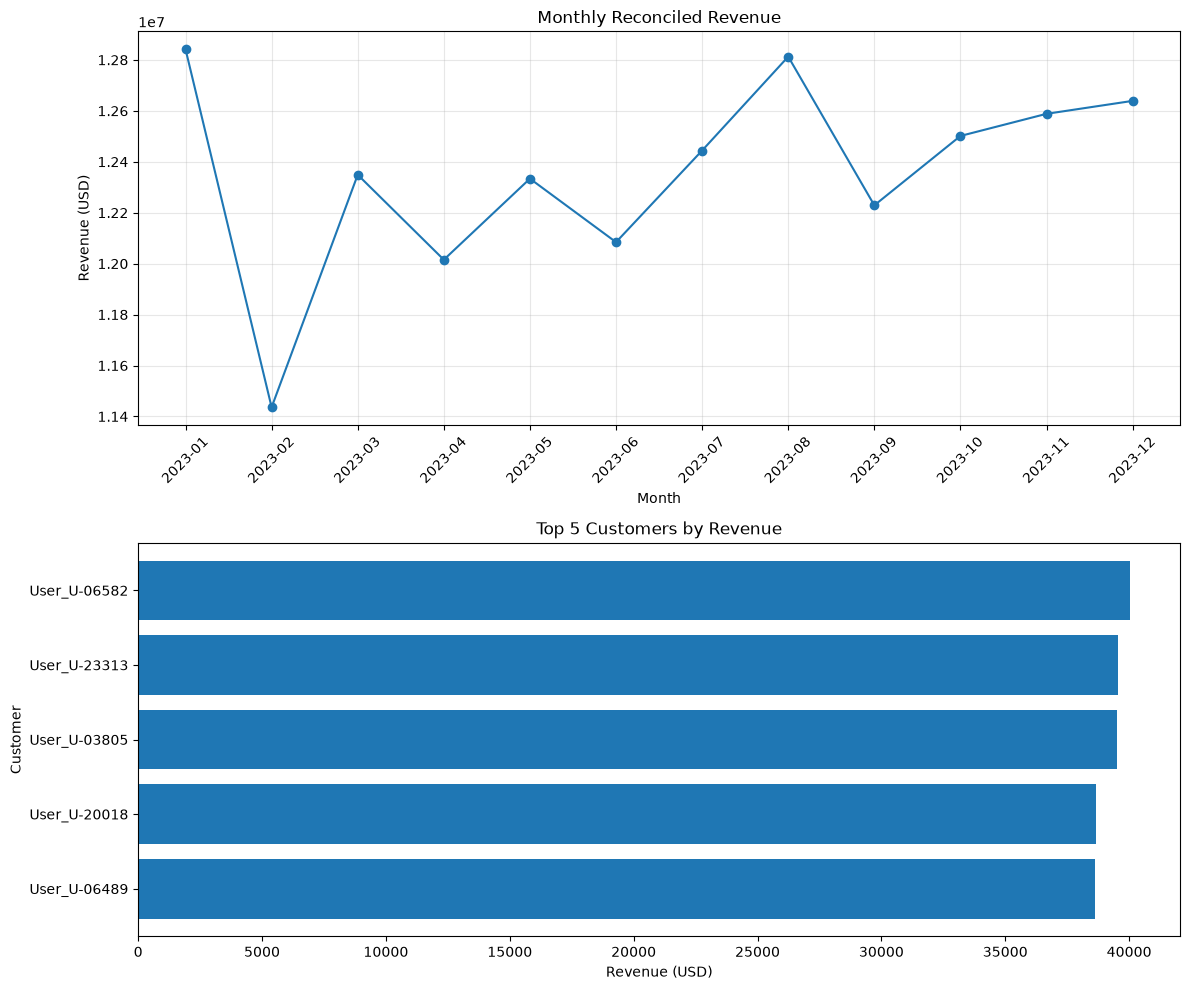

Dashboard saved to output/cfo_dashboard.png


In [43]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Chart 1: Monthly revenue
axes[0].plot(
    monthly_revenue["Month"],
    monthly_revenue["Total_USD_Revenue"],
    marker="o"
)

axes[0].set_title("Monthly Reconciled Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (USD)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

# Chart 2: Top five customers
top_sorted = top_5_customers.sort_values(
    "Total_USD_Revenue"
)

axes[1].barh(
    top_sorted["name"],
    top_sorted["Total_USD_Revenue"]
)

axes[1].set_title("Top 5 Customers by Revenue")
axes[1].set_xlabel("Revenue (USD)")
axes[1].set_ylabel("Customer")

plt.tight_layout()

plt.savefig(
    "output/cfo_dashboard.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved to output/cfo_dashboard.png")

In [44]:
print("FINAL PROJECT VALIDATION")
print("=" * 40)

print("Raw log records:", total_log_records)
print("Error records:", error_log_records)
print("Extracted transactions:", len(transactions))
print("Latest active customers:", len(active_users))
print("Exchange-rate records:", len(rates))
print("Missing exchange rates:", rates["EUR_to_USD"].isna().sum())
print("Reconciled transactions:", len(final_transactions))
print("Unique reconciled customers:", final_transactions["User_ID"].nunique())
print("Monthly report rows:", len(monthly_revenue))
print("Top customers listed:", len(top_5_customers))
print("Total reconciled revenue (USD):",
      round(final_transactions["USD_Revenue"].sum(), 2))

FINAL PROJECT VALIDATION
Raw log records: 100000
Error records: 5098
Extracted transactions: 94902
Latest active customers: 14183
Exchange-rate records: 365
Missing exchange rates: 0
Reconciled transactions: 53899
Unique reconciled customers: 13888
Monthly report rows: 12
Top customers listed: 5
Total reconciled revenue (USD): 148274622.91


In [45]:
import json

metrics = {
    "raw_log_records": int(total_log_records),
    "error_log_records_excluded": int(error_log_records),
    "parsed_transactions": int(len(transactions)),
    "latest_active_customers": int(len(active_users)),
    "exchange_rate_records": int(len(rates)),
    "missing_exchange_rates_after_fill": int(
        rates["EUR_to_USD"].isna().sum()
    ),
    "reconciled_transactions": int(len(final_transactions)),
    "unique_customers_with_transactions": int(
        final_transactions["User_ID"].nunique()
    ),
    "total_reconciled_usd_revenue": round(
        float(final_transactions["USD_Revenue"].sum()), 2
    )
}

with open("output/project_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print(json.dumps(metrics, indent=4))

{
    "raw_log_records": 100000,
    "error_log_records_excluded": 5098,
    "parsed_transactions": 94902,
    "latest_active_customers": 14183,
    "exchange_rate_records": 365,
    "missing_exchange_rates_after_fill": 0,
    "reconciled_transactions": 53899,
    "unique_customers_with_transactions": 13888,
    "total_reconciled_usd_revenue": 148274622.91
}


In [46]:
import pandas as pd
import json
from pathlib import Path

output_dir = Path("output")

print("=" * 45)
print("ENTERPRISE DATA RECONCILIATION")
print("FINAL OUTPUT VALIDATION")
print("=" * 45)

# Check required output files
required_files = [
    "active_users.csv",
    "clean_transactions.csv",
    "final_reconciled_transactions.csv",
    "monthly_revenue.csv",
    "top_5_customers.csv",
    "project_metrics.json",
    "cfo_dashboard.png"
]

print("\n1. OUTPUT FILE CHECK")

for filename in required_files:
    path = output_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

# Load output datasets
active = pd.read_csv(output_dir / "active_users.csv")
clean = pd.read_csv(output_dir / "clean_transactions.csv")
final = pd.read_csv(output_dir / "final_reconciled_transactions.csv")
monthly = pd.read_csv(output_dir / "monthly_revenue.csv")
top5 = pd.read_csv(output_dir / "top_5_customers.csv")

print("\n2. DATASET COUNTS")
print("Active customer rows:", len(active))
print("Clean transaction rows:", len(clean))
print("Final reconciled rows:", len(final))
print("Monthly summary rows:", len(monthly))
print("Top customer rows:", len(top5))

print("\n3. FINANCIAL VALIDATION")

print(
    "Total reconciled USD revenue:",
    round(final["USD_Revenue"].sum(), 2)
)

print(
    "Unique reconciled customers:",
    final["User_ID"].nunique()
)

print("\n4. DATA QUALITY CHECKS")

print(
    "Missing USD revenue values:",
    final["USD_Revenue"].isna().sum()
)

print(
    "Missing exchange rates:",
    final["EUR_to_USD"].isna().sum()
)

print(
    "Duplicate transaction rows:",
    final.duplicated().sum()
)

print("\n5. PROJECT METRICS")

with open(output_dir / "project_metrics.json", "r", encoding="utf-8") as file:
    metrics = json.load(file)

print(json.dumps(metrics, indent=4))

ENTERPRISE DATA RECONCILIATION
FINAL OUTPUT VALIDATION

1. OUTPUT FILE CHECK
active_users.csv: FOUND
clean_transactions.csv: FOUND
final_reconciled_transactions.csv: FOUND
monthly_revenue.csv: FOUND
top_5_customers.csv: FOUND
project_metrics.json: FOUND
cfo_dashboard.png: FOUND

2. DATASET COUNTS
Active customer rows: 14183
Clean transaction rows: 94902
Final reconciled rows: 53899
Monthly summary rows: 12
Top customer rows: 5

3. FINANCIAL VALIDATION
Total reconciled USD revenue: 148274622.91
Unique reconciled customers: 13888

4. DATA QUALITY CHECKS
Missing USD revenue values: 0
Missing exchange rates: 0
Duplicate transaction rows: 0

5. PROJECT METRICS
{
    "raw_log_records": 100000,
    "error_log_records_excluded": 5098,
    "parsed_transactions": 94902,
    "latest_active_customers": 14183,
    "exchange_rate_records": 365,
    "missing_exchange_rates_after_fill": 0,
    "reconciled_transactions": 53899,
    "unique_customers_with_transactions": 13888,
    "total_reconciled_usd_